##  Vincent Mui - October 2026

Capstone Assignment 20.1: Initial Report and Exploratory Data Analysis (EDA)

# Is Social Media Usage Hurting Mental Wellbeing?

![](images/02_Social_Media_User.jpg)

---

#### Index
- [Executive Summary](#overview)
- [CRISP-DM Framework](#crisp-dm-framework)
- [Business Understanding](#-Business-Understanding)
- [Data Understanding](#-Data-Understanding) 
    - [Exploratory Data Analysis](#exploratory-data-analysis)
    - [Data Description](#data-description)
    - [Visualization Part 1 (Raw Data)](#data-visualization----part-1)
- [Data Preparation](#-Data-Preparation)
    - [Data Cleaning/Transformation](#data-preparation-data-cleaning-and-transformation)
    - [Visualization Part 2 (Cleaned Data)](#data-visualization---part-2-cleanedtransformed-data)
- [Modeling](#modeling)
    - [A Simple Baseline Model](#a-simple-baseline-model)
- [Findings and Recommendation](#findings-and-recommendations)
- [Next Steps](#next-steps)

---

### Executive Summary

**Research Question** 

Is social media usage related to a user’s mental wellbeing? For example, are the number of hours spent daily on social media platforms related to the mental wellbeing score?

**Data Source** 

User data (e.g., age, gender, relationship status) and social media usage data (e.g., social media platform used, daily usage hours, time of use), and some mental wellbeing classification (e.g., wellbeing at risk?). A synthetic Kaggle dataset will be used: [Social Media Addiction & Mental Wellbeing Dataset](https://www.kaggle.com/datasets/harpartapsingh13/social-media-addiction-and-mental-wellbeing-dataset)

**Methodology** 

This project will follow the CRISP-DM framework. A subset of critical features will be selected and go through feature engineering. Different models will be applied: logistic regression, decision trees, KNN, random forests, and maybe Support Vector Machine (SVM with linear / Gaussian kernels). Grid search CV will be used to fine-tune hyper parameters, and error metrics will be used to select the best model.

**Expected Results**

The Machine Learning model should be able to tell what factors of social media usage (e.g., number of hours spent, age, night use) are related to a user’s mental wellbeing.

**Why This Question is Important** 

Understanding such factors will help business as well as public institutions:
- Businesses (markerters and advertisers) will understand how to effectively and responsibly use social media channels to advertise to their target audiences, with their mental wellbeing in mind.  E.g., reach target audience without negatively affecting their mental wellbeing.
- Public institutions can use the results to establish policies and guidelines for social media usage, to maintain good mental wellbeing of the general public. E.g., Parents/Social Media platforms may limit the hours spent on social media based on age group or time of use.  


---

### CRISP-DM Framework

<center>
    <img src = images/01_crisp-dm.png width = 50%/>
</center>


To frame the task, we will refer back to a standard process in industry for data projects called CRISP-DM.  This process provides a framework for working through a data problem.  

---

[Back to top](#-Index)

### Business Understanding

From a business perspective, we are tasked with identifying key factors related to a social media user’s mental wellbeing;
- User's demographics (e.g., age, gender, relationship status, etc.)
- User's social media usage (e.g., number of hours spent, night use, trys to cut down usage, etc.) 

#### Data Tasks
The business task can be reframed as the following data tasks:
- Is there one factor e.g., daily social usage hours (the independent variable) that is good for predicting the user's mental wellbeing (the dependent, outcome variable)?
- Which factors or variables (age, number of social platforms, night use, etc.) are the best predictors of the outcome variable (mental wellbeing)?
- How much do these independent variable(s) influence the outcome variable (mental wellbeing)? Can we use an algorithm to model the data to determine the magnitude and sign of such influences?

### Success Criteria
- Independent variable(s) identified for predicting user's mental wellbeing
- A machine learning model successfully selected to fit the data to determine the madnitude and sign of independent variables' influence. (based on objective criteria such as model scores/metrics)
- Business receommendations to businesses and institutions based on the data analysis and selected machine learning model

### Assumptions

- The question at hand is best framed as a "Classification" machine modeling problem
- `User_ID` is an unique indentifiers only, not independent "features" for predicting mental wellbeing
- `Addiction_Level` values were likely derived from `Daily_Usage_Hours`, so is conisdered redundant and not used as a predictor

---

[Back to top](#-Index)

### Data Understanding

#### Exploratory Data Analysis

Steps to understand the data
- Examine data using summary statistics
- Detect skewness, and outliers
- Identify data quality issues: missing values, duplicate rows, incorrect data types, inconsistent strings, etc.
- Use visual charts to and correlation checks to understand variable relationships

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from scipy import stats

## scikit-learn imports, grouped by role
from sklearn.model_selection import (train_test_split, GridSearchCV, StratifiedKFold, cross_val_predict)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             classification_report, roc_curve, precision_recall_curve,
                             ConfusionMatrixDisplay)

from sklearn import set_config

set_config(display = "diagram") # setting this to display pipelines


In [2]:
data = pd.read_csv('data/social_media_addiction_mental_wellbeing.csv')

In [3]:
# Explore metadata information
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 30 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   User_ID                       1500 non-null   str    
 1   Age                           1500 non-null   int64  
 2   Gender                        1447 non-null   str    
 3   Occupation                    1455 non-null   str    
 4   Relationship_Status           1449 non-null   str    
 5   Primary_Platform              1447 non-null   str    
 6   Daily_Usage_Hours             1444 non-null   float64
 7   Platforms_Used_Count          1500 non-null   int64  
 8   Posts_Per_Week                1500 non-null   int64  
 9   Late_Night_Usage              1450 non-null   str    
 10  First_Check_Morning           1500 non-null   str    
 11  Notifications_Per_Day         1500 non-null   int64  
 12  FOMO_Score                    1445 non-null   float64
 13  Social_Compari

In [4]:
# Take a look at actual data (last 5 rows)
data.tail()

,User_ID,Age,Gender,Occupation,Relationship_Status,Primary_Platform,Daily_Usage_Hours,Platforms_Used_Count,Posts_Per_Week,Late_Night_Usage,...,Loneliness_Score,Self_Esteem_Score,Sleep_Quality_Score,Sleep_Hours,Productivity_Loss_Score,Offline_Relationship_Quality,Physical_Activity_Hrs_Week,Screen_Free_Time_Hrs,Mental_Wellbeing_Score,Addiction_Level
1495,USR01496,40,Male,Working Professional,In a Relationship,TikTok,2.7,2,4,No,...,3.3,7.4,8.5,6.7,4.5,7.6,2.3,2.3,6.5,High
1496,USR01497,23,Non-binary,Student,Married,YouTube,3.5,3,6,Yes,...,4.2,1.9,7.2,6.9,7.2,NaN,2.8,2.0,6.4,Moderate
1497,USR01498,39,Female,Student,Single,Instagram,5.3,2,3,Yes,...,0.4,2.4,5.1,NaN,6.4,7.8,2.6,4.8,4.7,Severe
1498,USR01499,26,Female,Freelancer,Single,Twitter/X,7.3,4,0,Yes,...,7.5,6.6,6.4,4.2,9.1,6.4,3.6,2.1,6.4,High
1499,USR01500,16,Female,Working Professional,In a Relationship,TikTok,0.7,3,2,No,...,5.9,8.5,5.3,7.2,3.4,2.3,3.9,3.1,6.1,Moderate


In [5]:
# Summary statistics for numeric columns
data.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Age,1500.0,29.37,8.55,15.0,22.0,29.0,37.00,44.0
Daily_Usage_Hours,1444.0,4.52,2.11,0.5,3.1,4.4,5.90,12.0
Platforms_Used_Count,1500.0,3.24,1.68,1.0,2.0,3.0,4.00,8.0
Posts_Per_Week,1500.0,3.94,1.95,0.0,3.0,4.0,5.00,12.0
Notifications_Per_Day,1500.0,60.24,33.15,5.0,36.0,59.0,81.25,165.0
FOMO_Score,1445.0,5.45,2.18,0.0,4.0,5.5,7.00,10.0
Social_Comparison_Score,1449.0,5.50,2.04,0.0,4.1,5.5,6.90,10.0
Validation_Seeking_Score,1442.0,5.01,2.11,0.0,3.6,5.0,6.50,10.0
Scroll_Without_Purpose,1500.0,5.45,2.08,0.0,4.0,5.5,6.90,10.0
Anxiety_Score,1452.0,5.11,2.16,0.0,3.7,5.1,6.60,10.0


Initial Observation: summary statitics

- All "Score" related columns have a scale of 0 to 10
- Some numeric columns seem to have outliers: Notifications_Per_Day, etc.  Will investigate further below.

In [6]:
# Descriptive statistics for categorical columns
data.describe(include=["object"]).T

,count,unique,top,freq
User_ID,1500,1500,USR00001,1
Gender,1447,3,Male,658
Occupation,1455,4,Student,579
Relationship_Status,1449,3,Single,624
Primary_Platform,1447,6,Instagram,399
Late_Night_Usage,1450,2,Yes,774
First_Check_Morning,1500,3,Within 5 min,685
Tried_To_Cut_Back,1459,2,Yes,815
Failed_To_Cut_Back,1457,2,No,752
Addiction_Level,1500,4,Moderate,450


Initial Observation: There are not many unique values in each categorical column, meaning there may not be too many "invalid" values to be cleanup up. Will check via visual inspections in below EDA section.

In [7]:
# Perform actual EDA

print("="*100)
print("DATA UNDERSTANDING: EXPLORATORY DATA ANALYSIS")
print("="*100)

# 1. Original dataset dimensions
print("1. Total number of raw data rows and columns:", data.shape)
print("-"*100)

# 2. Investigate duplicates
print("2. Number of duplicate rows:", data.duplicated().sum())
print("-"*100)

# 3. Detect outliers using Z-score
select_numeric_df = data[['Daily_Usage_Hours', 'Platforms_Used_Count', 'Posts_Per_Week', 'Notifications_Per_Day']]
z_scores = np.abs(stats.zscore(select_numeric_df))
# Set threshold to 3 standard deviations (far from the Mean)
threshold = 3
outliers_df = select_numeric_df[z_scores > threshold]
print("3. Number of outliers:", outliers_df.shape[0])
print("-"*100)
# COMMENTED OUT to conform to "No long strings of code output" guideline
# print("Outliers:", outliers_df)

# 4. Investigate useless column(s), after studying describe() statistics from above
print("4. Not useful data column - does not provide information to predict price outcome")
print("   'User_ID' column data type:", data.User_ID.dtype, ", count of unique values:", data["User_ID"].unique().size)
print("-"*100)

# 5. Investigate missing values
print("5. Missing values")
print("   Number of missing value in each column:\n", data.isnull().sum().sort_values(ascending=False))
print("-"*100)

# 6. Inspect (visually) possible incorrect data types or bad data values
data_col_list = data.select_dtypes(include=["object"]).drop(['User_ID'], axis=1).columns.tolist()
print("6. Possible incorrect data types and bad values")
print(data_col_list)
# Compare columns with string data type and its values

# COMMENTED OUT to conform to "No long strings of code output" guideline
print("   Long output dropped after visual inspection to keep notebook clean and readable")
# for x in data_col_list:
#    print(x, "column - string values:", data[x].unique())
#    print("+"*96)

print("-"*100)


DATA UNDERSTANDING: EXPLORATORY DATA ANALYSIS
1. Total number of raw data rows and columns: (1500, 30)
----------------------------------------------------------------------------------------------------
2. Number of duplicate rows: 0
----------------------------------------------------------------------------------------------------
3. Number of outliers: 14
----------------------------------------------------------------------------------------------------
4. Not useful data column - does not provide information to predict price outcome
   'User_ID' column data type: str , count of unique values: 1500
----------------------------------------------------------------------------------------------------
5. Missing values
   Number of missing value in each column:
 Offline_Relationship_Quality    70
Self_Esteem_Score               69
Sleep_Quality_Score             68
Sleep_Hours                     62
Screen_Free_Time_Hrs            60
Validation_Seeking_Score        58
Daily_Usage_Hour

---

Perform further investigation into missing values

In [8]:
# Compute percentage of "missing values" within total observations for top few columns
# Check if percentage of missing data > 30% => meet criteria for dropping column
offline_rel_quality_miss_pct = round(data["Offline_Relationship_Quality"].isnull().sum()/data.shape[0]*100, 2)
self_esteem_score_miss_pct = round(data["Self_Esteem_Score"].isnull().sum()/data.shape[0]*100, 2)
sleep_quality_score_miss_pct = round(data["Sleep_Quality_Score"].isnull().sum()/data.shape[0]*100, 2)
sleep_hours_miss_pct = round(data["Sleep_Hours"].isnull().sum()/data.shape[0]*100, 2)

print("="*100)
print("5.a FURTHER DATA INVESTIGATION: MISSING VALUES")
print("="*100)
print("Percentage of missing 'Offline_Relationship_Quality' values vs. total:", offline_rel_quality_miss_pct, "%")
print("Percentage of missing 'Self_Esteem_Score' values vs. total:", self_esteem_score_miss_pct, "%")
print("Percentage of missing 'Sleep_Quality_Score' values vs. total:", sleep_quality_score_miss_pct, "%")
print("Percentage of missing 'Sleep_Hours' values vs. total:", sleep_hours_miss_pct, "%")
print("Drop whole 'size' column if > 30%? =", True if offline_rel_quality_miss_pct > 30 else False)
print("-"*100)


5.a FURTHER DATA INVESTIGATION: MISSING VALUES
Percentage of missing 'Offline_Relationship_Quality' values vs. total: 4.67 %
Percentage of missing 'Self_Esteem_Score' values vs. total: 4.6 %
Percentage of missing 'Sleep_Quality_Score' values vs. total: 4.53 %
Percentage of missing 'Sleep_Hours' values vs. total: 4.13 %
Drop whole 'size' column if > 30%? = False
----------------------------------------------------------------------------------------------------


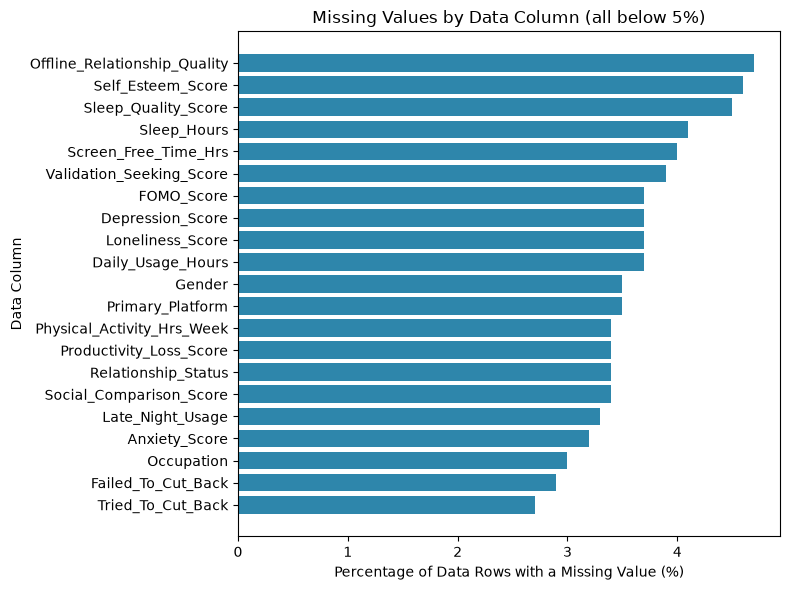

In [9]:
# Bar Chart to visualize missing value percentages

missing_pct_df = (data.isna().mean() * 100).round(1)
missing_pct_df = missing_pct_df[missing_pct_df > 0].sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(missing_pct_df.index, missing_pct_df.values, color="#2e86ab")
ax.set_xlabel("Percentage of Data Rows with a Missing Value (%)")
ax.set_ylabel("Data Column")
ax.set_title("Missing Values by Data Column (all below 5%)")
plt.tight_layout()
plt.show()

#### Further Data Investigation Findings

Missting Values Percentages

- No data columns have more than 30% missing values, therefore no need to drop any entire column.
- Columns have at most 4.67% missing values (no more than 5%), and nothing looks systematic, so we keep every row. These missing values will be filled/replaced **inside each cross-validation fold** during our Modeling step (median for numberic data, "Unknown" for categorical data), so nothing from the test data leaks into training our model(s).  Dropping all data rows with missing values will drop more than 800 rows (> 50% of our valuable data), therefore not recommended in this case.

"Addiction_Level" column has 4 ordinal values:

- 'low', 'Moderate', 'High', 'Severe'
- therefore *may* be encoded into numbers by ranks (See Data Preparation section)

---

#### Data Description

Here are the column descriptions for *business* data understanding, after data exploration. 

Some data columns are features (user demographics, user usage habits), and other data columns are user's mental state measurements (different scores)

~~~
Total 1,500 data rows, 30 data columns:

 #   Column                Missing Values  Type     Description 
---  ------                --------------  -----    ------------
 0   User_ID                       0	   String   Unique User ID
 1   Age                           0	   Numeric  User's Age: 15 - 44
 2   Gender                        53 	   String   User's Gender: Male, Female, Non-binary
 3   Occupation                    45	   String   Working Professional, Student, Unemployed, etc.
 4   Relationship_Status           51	   String   Single, Married, In a Relationship
 5   Primary_Platform              53	   String   YouTube, Instagram, Facebook, TikTok, Twitter/X, Snapchat
 6   Daily_Usage_Hours             56	   Numeric  Daily Social Media Usage in hours (0.5 to 12)
 7   Platforms_Used_Count          0	   Numeric  Number of social platforms used (1 to 8)
 8   Posts_Per_Week                0	   Numeric  Number of social posts published per week (0 to 12)
 9   Late_Night_Usage              50	   String   Late night social media usage (Yes/No)
 10  First_Check_Morning           0	   String   First check in morning: Within 5 min, 5-30 min, After 30 min
 11  Notifications_Per_Day         0 	   Numeric  Notifications per day (5 - 165)
 12  FOMO_Score                    55	   Numeric  "Fear of Missing Out" score (0 to 10)
 13  Social_Comparison_Score       51 	   Numeric  Social comparison to others score (0 to 10)
 14  Validation_Seeking_Score      58	   Numeric  Validation-seeking score (0 to 10)
 15  Scroll_Without_Purpose        0 	   Numeric  Dumb scrolling score (0 to 10)
 16  Tried_To_Cut_Back             41	   String   User has tried to cut back on social (Yes/No)
 17  Failed_To_Cut_Back            43	   String   User has failed to cut back on social (Yes/No)
 18  Anxiety_Score                 48	   Numeric  Anxiety Score (0 to 10)
 19  Depression_Score              55	   Numeric  Depression Score (0 to 10)
 20  Loneliness_Score              55	   Numeric  Loneliness Score (0 to 10)
 21  Self_Esteem_Score      	   69	   Numeric  Self-Esteem Score (0 to 10)
 22  Sleep_Quality_Score           68	   Numeric  Sleep Quality Score (0 to 10)
 23  Sleep_Hour                    62	   Numeric  Sleep Hours	per day (3 to 10)
 24  Productivity_Loss_Score       51	   Numeric  Productivity loss score (0 to 10)
 25  Offline_Relationship_Quality  70	   Numeric  Offline relationship quality score 
 26  Physical_Activity_Hrs_Week    51	   Numeric  Hours of physical activity per week (0 - 8.9)
 27  Screen_Free_Time_Hrs          60	   Numeric  Number of Screen-Free Time in hours (0 - 10.3)
 28  Mental_Wellbeing_Score        0       Numeric  Our "Target": Mental Wellbeing Score (0 to 10)
 29  Addiction_Level               0 	   String   Social Media Addiction Level: Low, Severe, High, Moderate


---

#### Data Visualization  - Part 1

Visual charts to understand variable relationships

We want to explore how mental wellbeing relates to user demographics and social-media usage habits, *before* modeling

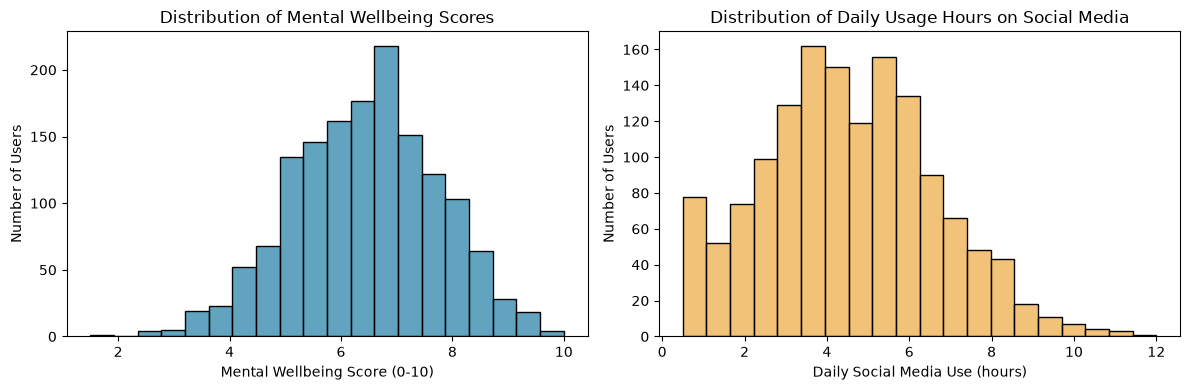

In [10]:
# Histograms to visualize distributions of target variable `Mental_Wellbeing_Score` and feature `Daily_Usage_Hours`

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data.Mental_Wellbeing_Score, bins=20, color="#2e86ab", ax=axes[0])
axes[0].set_xlabel("Mental Wellbeing Score (0-10)")
axes[0].set_ylabel("Number of Users")
axes[0].set_title("Distribution of Mental Wellbeing Scores")
sns.histplot(data.Daily_Usage_Hours, bins=20, color="#edae49", ax=axes[1])
axes[1].set_xlabel("Daily Social Media Use (hours)")
axes[1].set_ylabel("Number of Users")
axes[1].set_title("Distribution of Daily Usage Hours on Social Media")
plt.tight_layout()
plt.savefig("images/wellbeing_hours_dist_plots.png")
plt.show()

Observations:
- `Mental Wellbeing Score` shows a close to normal distribution
- `Daily_Usage_Hours` - distribution is slightly Right-Skewed

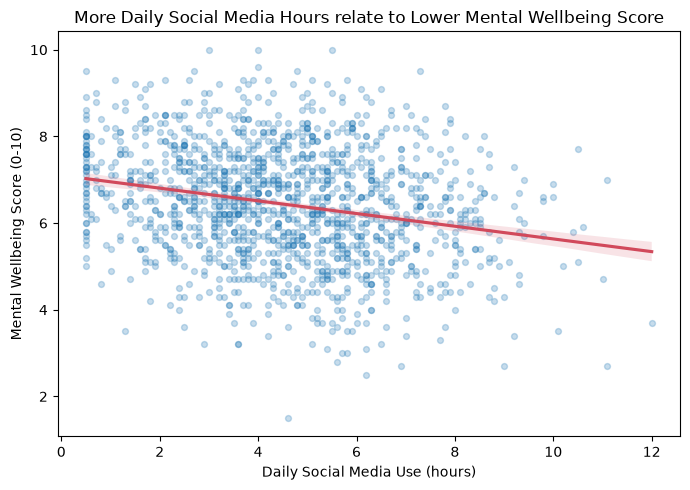

In [11]:
# Seaborn scatter plot with linear regression model to visualize relationship between `Daily_Usage_Hours` and `Mental_Wellbeing_Score`

fig, ax = plt.subplots(figsize=(7, 5))
daily_usage_df = data[["Daily_Usage_Hours", "Mental_Wellbeing_Score"]].dropna()
sns.regplot(data=daily_usage_df, x=daily_usage_df.Daily_Usage_Hours, y=daily_usage_df.Mental_Wellbeing_Score, scatter_kws={"alpha": 0.25, "s": 18}, line_kws={"color": "#d1495b"}, ax=ax)
ax.set_xlabel("Daily Social Media Use (hours)")
ax.set_ylabel("Mental Wellbeing Score (0-10)")
ax.set_title("More Daily Social Media Hours relate to Lower Mental Wellbeing Score")
plt.tight_layout()
plt.savefig("images/hour_vs_wellbeing_plot1.png")
plt.show()

Observation:
- Higher `Daily Social Media Hours` are related to lower `Mental Wellbeing Score` (See fitted red model line) 


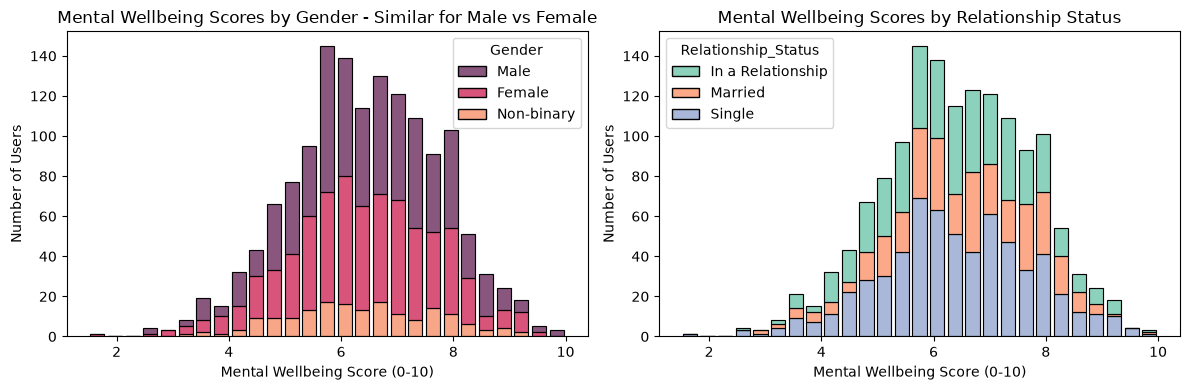

In [12]:
# Stacked histograms to visualize Mental Wellbeing Score distribution among:
#   Gender Groups, and 
#   relationship statuses

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=data, x="Mental_Wellbeing_Score", 
            hue="Gender", multiple="stack",
            shrink=0.8,  # Adds spacing between bars so it looks like a bar chart
            palette="rocket", ax=axes[0]
)
axes[0].set_xlabel("Mental Wellbeing Score (0-10)")
axes[0].set_ylabel("Number of Users")
axes[0].set_title("Mental Wellbeing Scores by Gender - Similar for Male vs Female")
sns.histplot(data=data, x="Mental_Wellbeing_Score", 
            hue="Relationship_Status", multiple="stack",
            shrink=0.8,  # Adds spacing between bars so it looks like a bar chart
            palette="Set2", ax=axes[1]
)
axes[1].set_xlabel("Mental Wellbeing Score (0-10)")
axes[1].set_ylabel("Number of Users")
axes[1].set_title("Mental Wellbeing Scores by Relationship Status")
plt.tight_layout()
plt.savefig("images/wellbeing_gender_relat_plot.png")
plt.show()

Observations:

Gender and Relationships Status do not affect Mental Wellbeing Scores distribution much
- `Mental Wellbeing Score` values are close to evenly distributed among majority `Gender` groups, namely Male and Female, across the scoring range of 0 - 10.
- `Relationship Status`: we see a slightly higher proportions of "Single" users for mental wellbeing scoring range of 5 - 7, and "Married" and "In a Relationship" share similar distributions.

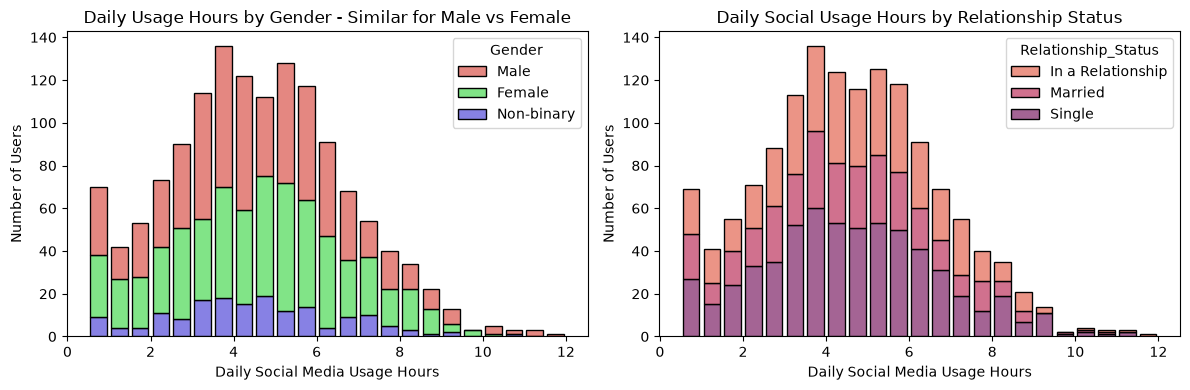

In [13]:
# Stacked histograms to visualize Daily Usage Hours distribution among:
#   Gender Groups, and 
#   relationship statuses

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=data, x="Daily_Usage_Hours", 
            hue="Gender", multiple="stack",
            shrink=0.8,  # Adds spacing between bars so it looks like a bar chart
            palette="hls", ax=axes[0]
)
axes[0].set_xlabel("Daily Social Media Usage Hours")
axes[0].set_ylabel("Number of Users")
axes[0].set_title("Daily Usage Hours by Gender - Similar for Male vs Female")
sns.histplot(data=data, x="Daily_Usage_Hours", 
            hue="Relationship_Status", multiple="stack",
            shrink=0.8,  # Adds spacing between bars so it looks like a bar chart
            palette="flare", ax=axes[1]
)
axes[1].set_xlabel("Daily Social Media Usage Hours")
axes[1].set_ylabel("Number of Users")
axes[1].set_title("Daily Social Usage Hours by Relationship Status")
plt.tight_layout()
plt.savefig("images/usage_gender_relat_plot.png")
plt.show()

Observations:

- Daily Social Media Usage habits are similar among major `Gender` groups, namely Male and Female, 
- `Relationship Status`: we see a slightly higher proportions of "Single" users across Daily Social Media Usage Hours spectrum. Likely due to Single users have more spare time to use Social Media daily.

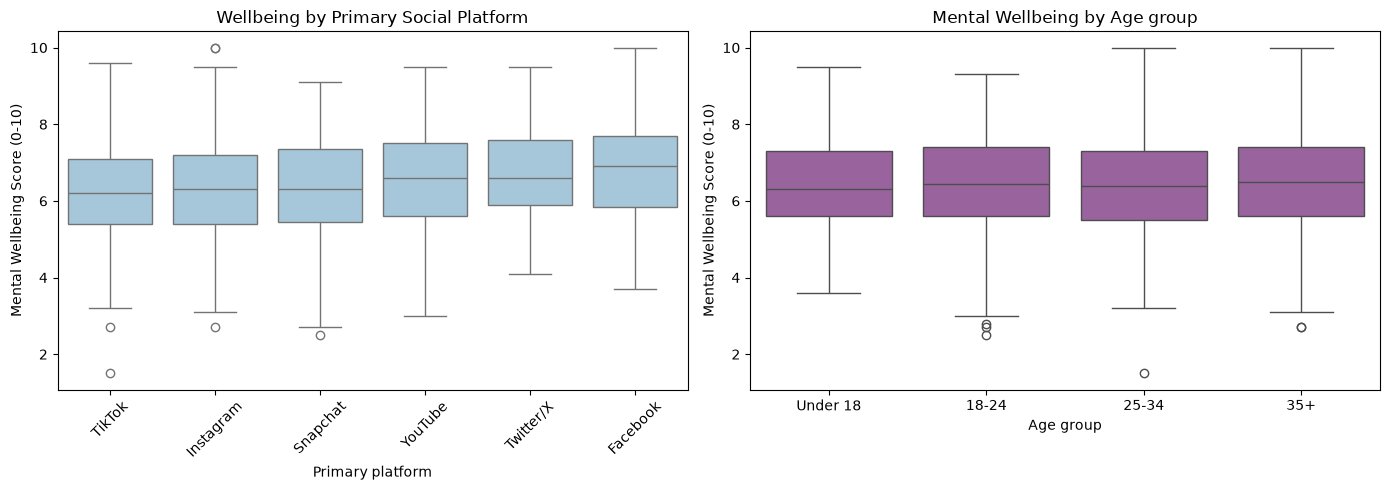

In [14]:
# Box plots to visualize relationships of target variable "Mental_Wellbeing_Score" and:
# User's Age group
# User's primary social media platform

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_data = data[["Primary_Platform", "Age", "Mental_Wellbeing_Score"]].copy()
platform_order = plot_data.groupby("Primary_Platform")["Mental_Wellbeing_Score"].mean().sort_values().index
sns.boxplot(data=plot_data, x="Primary_Platform", y="Mental_Wellbeing_Score", order=platform_order, color="#9ecae1", ax=axes[0])
axes[0].set_xlabel("Primary platform")
axes[0].set_ylabel("Mental Wellbeing Score (0-10)")
axes[0].set_title("Wellbeing by Primary Social Platform")
axes[0].tick_params(axis="x", rotation=45)

plot_data["age_group"] = pd.cut(plot_data["Age"], [0, 17, 24, 34, 200], labels=["Under 18", "18-24", "25-34", "35+"])
sns.boxplot(data=plot_data, x="age_group", y="Mental_Wellbeing_Score", color="#a15ba6c8", ax=axes[1])
axes[1].set_xlabel("Age group")
axes[1].set_ylabel("Mental Wellbeing Score (0-10)")
axes[1].set_title("Mental Wellbeing by Age group")
plt.tight_layout()
plt.show()

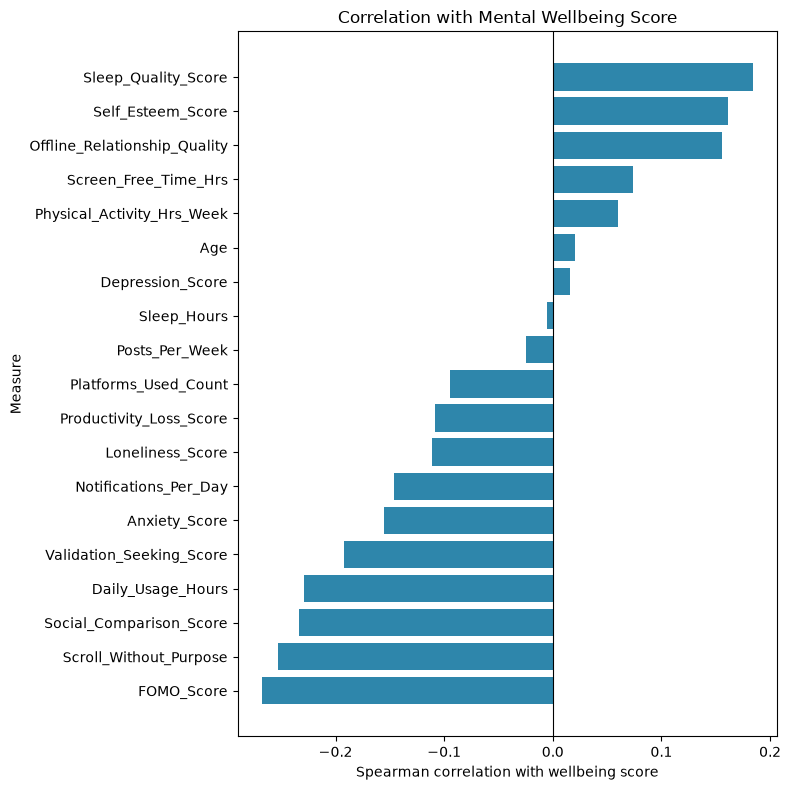

In [15]:
# Correlation plot to visualize which numeric features (demographics, habits) and measures (scores) move with our target mental wellbeing
numeric_df = [c for c in data.select_dtypes("number").columns if c not in ["User_ID"] + ["Mental_Wellbeing_Score"]]
corr = data[numeric_df + ["Mental_Wellbeing_Score"]].corr(method="spearman")["Mental_Wellbeing_Score"].drop("Mental_Wellbeing_Score").sort_values()

fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(corr.index, corr.values, color="#2e86ab")
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Spearman correlation with wellbeing score")
ax.set_ylabel("Measure")
ax.set_title("Correlation with Mental Wellbeing Score")
plt.tight_layout()
plt.savefig("images/corr_wellbeing_plot.png")
plt.show()

Observations:
- Bad user habits decrease mental wellbeing: more `Daily Social Media Hours` and `Scroll_Without_Purpose` relate to lower `Mental Wellbeing Score` (See fitted red model line in scatter plot, and correlation plot)
- Good user habits improve mental wellbeing: more `Screen_Free_Time_Hrs` and `Physical_Activity_Hrs_Week` related to higher `Mental Wellbeing Score`


---

[Back to top](#-Index)

### Data Preparation

After our initial exploration and fine-tuning of the business understanding, it is time to construct our final dataset prior to modeling.  Here, we want to make sure to handle any integrity issues and cleaning, the engineering of new features, any transformations that we believe should happen (scaling, logarithms, normalization, etc.), and general preparation for modeling with `sklearn`. 


#### Data Preparation: Data Cleaning and Transformation

Steps to construct final dataset prior to modeling:

Missing or Bad Values
- No data columns have more than 30% missing values, therefore no need to drop any entire column.
- Columns have at most 4.67% missing values (no more than 5%), and nothing looks systematic, so we keep every data row. These missing values will be filled/replaced **inside each cross-validation fold** during our Modeling step. We will drop rows with missing values for 3 boolean categorical features columns only (see Feature Engineering below); dropping all data rows with missing values will drop more than 800 rows (> 50%), therefore not recommended.
- There are no other values detected from exploration that need to be dropped e.g., "others", "unknown" or "custom".
- There are no data rows with missing target values `Mental_Wellbeing_Score`.
- There are no "bad" categorical values that need cleanup

Drop Data Columns
- Drop Columns with useless data
  - `User_ID` (Unique IDs do not help predict outcome)
  - `Addiction_Level` (likely derived from Daily_Usage_Hours, so redundant)
- Drop the followig data columns; they are **not** deemed as "features", because they are **not** social media behavior or habits.  They are variations of mental state measurement scores (likely the other "outcomes" for a different project):
  - `Anxiety_Score` 
  - `Depression_Score`
  - `Loneliness_Score`
  - `Self_Esteem_Score`
  - `Sleep_Quality_Score` 
  - `Productivity_Loss_Score`

Duplicate Rows
- There are no duplicate rows for cleanup.

Feature Engineering
- Classification Target Variable: For this project, we want to classify `Mental_Wellbeing_Score` into three groups:
  - High - Top third of scores
  - Low - Bottom third of scores
  - Medium - The rest of scores
- Convert boolean categorical features to numeric (0/1), during **Modeling** step. Will drop rows with missing values for these columns, not others.
  - `Late_Night_Usage`
  - `Tried_To_Cut_Back` 
  - `Failed_To_Cut_Back`

Encoding
- Apply OneHotEncoder to remaining categorical columns for regression models
- Although `Addiction_Level` column has 4 ordinal values: 'low', 'Moderate', 'High', 'Severe', there is no need to encode them into ranking numbers, because this data column is considered derived from Daily_Usage_Hours, so will not be used in modeling.

Outliers
- Apply Interquartile range (IQR = 𝑄3 − 𝑄1 ) to detect outliers for elimination
- Apply to numeric columns: `Daily_Usage_Hours, Platforms_Used_Count, Posts_Per_Week, Notifications_Per_Day`

Scaling
- For this exercise, data scaling will be performed during the **Modeling** step of CRSIP-DM framework
- Will check if log transformation of data is needed by visual plots.

Cross-validation (will be performed in later **Modeling** step)
- Train / Test Split: create a holdout "test set" for cross-validation to assess models' performance


In [16]:
# Make a copy of original data before data transformation and cleaning
clean_data = data.copy()

In [17]:
# Drop whole data column for "User_ID", "Addiction_Level", and other score columns not used for modeling
clean_data.drop(columns = ["User_ID", "Addiction_Level", 
                           "Anxiety_Score", "Depression_Score", 
                           "Loneliness_Score", "Self_Esteem_Score", 
                           "Sleep_Quality_Score", "Productivity_Loss_Score"
                           ], inplace = True)

# Drop rows (not columns) with missing values for only the 3 boolean categorical columns
boo_col_list = ["Late_Night_Usage", "Tried_To_Cut_Back", "Failed_To_Cut_Back"]
clean_data.dropna(subset=boo_col_list, inplace = True)

print("Resulting numbers of rows and colunms:", clean_data.shape)

Resulting numbers of rows and colunms: (1372, 22)


---

The Target: Three Mental Wellbeing Groups

For this project, we want to classify Mental Wellbeing Scores into three groups, using quantiles:
- High - Top third of scores
- Low - Bottom third of scores
- Medium - The rest of scores

We will use a bar plot to visualize the distribution of these groups/classes

In [18]:
# Transform numeric Mental_Wellbeing_Score into three categorical values:
#  High - Top third of scores (green)
#  Low - Bottom third of scores (red)
#  Medium - The rest of scores (orange)

classes = ["Low", "Medium", "High"]
low_cut, high_cut = data.Mental_Wellbeing_Score.quantile([1 / 3, 2 / 3])
color_palette = {"Low": "red", "Medium": "orange", "High": "green"}

# Create new categorical column wellbeing_class
clean_data["wellbeing_class"] = pd.cut(clean_data.Mental_Wellbeing_Score, 
                                       [-np.inf, low_cut, high_cut, np.inf], 
                                       labels=classes, right=False).astype(str)
# Remove old numeric column Mental_Wellbeing_Score
clean_data.drop(columns = ["Mental_Wellbeing_Score"], inplace = True)

print("="*100)
print("Target Variable: Mental Wellbeing Class Balance")
print("="*100)
print(f"Low: score < {low_cut:.2f} | Medium: in between | High: score >= {high_cut:.2f}")
print("="*100)


Target Variable: Mental Wellbeing Class Balance
Low: score < 5.90 | Medium: in between | High: score >= 7.00


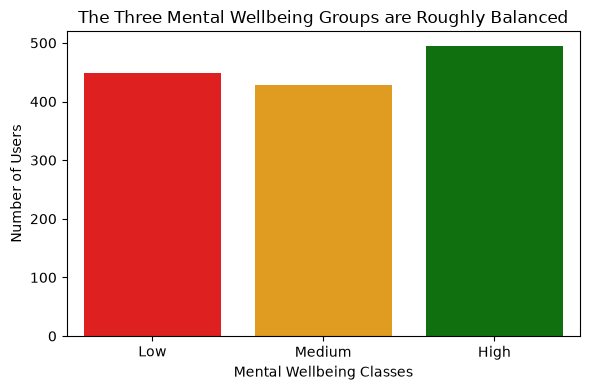

In [19]:
# Bar chart to visualize target class distribution

class_counts = clean_data["wellbeing_class"].value_counts().reindex(classes)
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=class_counts.index, y=class_counts.values, palette=color_palette, ax=ax)
ax.set_xlabel("Mental Wellbeing Classes")
ax.set_ylabel("Number of Users")
ax.set_title("The Three Mental Wellbeing Groups are Roughly Balanced")
plt.tight_layout()
plt.savefig("images/wellbeing_class_plot.png")
plt.show()


Observation: 

The 3 Mental Wellbeing classes (High, Medium, Low) are roughly balanced

---

In [20]:
# Clean up outliers, using Interquartile range (IQR = 𝑄3 − 𝑄1 )

outlier_list = ['Daily_Usage_Hours', 'Platforms_Used_Count', 'Posts_Per_Week', 'Notifications_Per_Day']
for column_name in outlier_list:
    q_1 = clean_data[column_name].quantile(.25)
    q_3 = clean_data[column_name].quantile(.75)
    iqr = q_3 - q_1
    lower = q_1 - (1.5 * iqr)
    upper = q_3 + (1.5 * iqr)
    clean_data = clean_data.loc[(clean_data[column_name] > lower) & (clean_data[column_name] < upper)]

print("="*100)
print("Select Columns with Outliers Removed")
print("="*100)
print(clean_data[outlier_list].describe().T.round(2))
print("="*100)

Select Columns with Outliers Removed
                        count   mean    std  min   25%   50%   75%    max
Daily_Usage_Hours      1163.0   4.48   2.07  0.5   3.0   4.4   5.9   10.0
Platforms_Used_Count   1163.0   3.03   1.44  1.0   2.0   3.0   4.0    6.0
Posts_Per_Week         1163.0   3.79   1.63  1.0   3.0   4.0   5.0    7.0
Notifications_Per_Day  1163.0  60.10  33.13  5.0  36.0  59.0  81.0  147.0


In [21]:
## Data Cleaning and Transformation Audit

print("="*100)
print("DATA PREPARATION: DATA CLEANING AND TRANSFORMATION AUDIT")
print("="*100)
print("Total number of original data rows and columns:           ", data.shape)
print("After cleaning and feature engineering - rows and columns:", clean_data.shape)
# Post cleaning outliers using Z-score
select_numeric_df2 = clean_data[outlier_list]
z_scores = np.abs(stats.zscore(select_numeric_df2))
threshold = 3   # Set threshold to 3 standard deviations again
outliers_df2 = select_numeric_df2[z_scores > threshold]
print("Number of outliers in original columns:", outliers_df.shape[0])
print("Number of outliers in cleaned columns: ", outliers_df2.shape[0])
print("-"*100)
print(clean_data.info())
print("="*100)

DATA PREPARATION: DATA CLEANING AND TRANSFORMATION AUDIT
Total number of original data rows and columns:            (1500, 30)
After cleaning and feature engineering - rows and columns: (1163, 22)
Number of outliers in original columns: 14
Number of outliers in cleaned columns:  0
----------------------------------------------------------------------------------------------------
<class 'pandas.DataFrame'>
Index: 1163 entries, 0 to 1499
Data columns (total 22 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Age                           1163 non-null   int64  
 1   Gender                        1120 non-null   str    
 2   Occupation                    1127 non-null   str    
 3   Relationship_Status           1124 non-null   str    
 4   Primary_Platform              1119 non-null   str    
 5   Daily_Usage_Hours             1163 non-null   float64
 6   Platforms_Used_Count          1163 non-null   int

---

#### Data Visualization - Part 2 (Cleaned/Transformed Data)

Charts to visualize any possible relationships between cleaned/transformed data columns

In [22]:
# Make a copy of cleaned data before manipulations for various plots
plot_data = clean_data.copy()

1493    2-4 h
1495    2-4 h
1496    2-4 h
1497    4-6 h
1499    < 2 h
Name: daily_hours_band, dtype: category
Categories (6, str): ['< 2 h' < '2-4 h' < '4-6 h' < '6-8 h' < '8-10 h' < '10+ h']


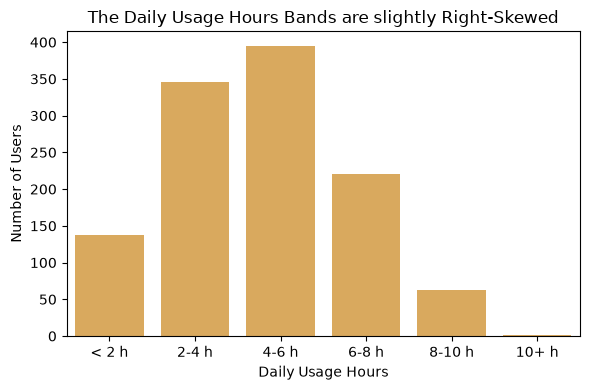

In [23]:
# Bar chart to visualize usage hour bands

# Create a daily usage hour band column
bands = ["< 2 h", "2-4 h", "4-6 h", "6-8 h", "8-10 h", "10+ h"]
plot_data["daily_hours_band"] = pd.cut(plot_data["Daily_Usage_Hours"], [0, 2, 4, 6, 8, 10, 20], labels=bands, right=False)

print(plot_data["daily_hours_band"].tail())

hour_counts = plot_data["daily_hours_band"].value_counts().reindex(bands)
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=hour_counts.index, y=hour_counts.values, color="#edae49", ax=ax)
ax.set_xlabel("Daily Usage Hours")
ax.set_ylabel("Number of Users")
ax.set_title("The Daily Usage Hours Bands are slightly Right-Skewed")
plt.tight_layout()
plt.savefig("images/hour_band_plot.png")
plt.show()

Observation: 

The Daily Usage Hours are slightly right-skewed, just like what we observed in the previous histogram plot.

---

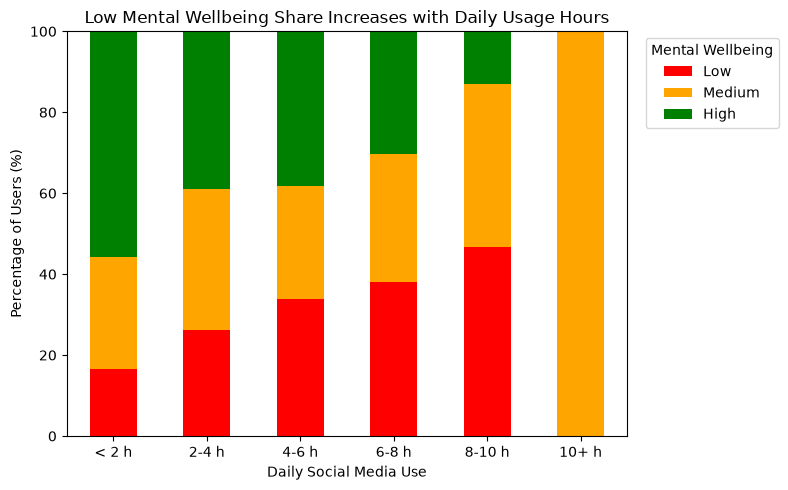

wellbeing_class,Low,Medium,High
daily_hours_band,,,
< 2 h,16.7,27.5,55.8
2-4 h,26.3,34.7,39.0
4-6 h,33.9,27.8,38.2
6-8 h,38.0,31.7,30.3
8-10 h,46.8,40.3,12.9
10+ h,0.0,100.0,0.0


In [24]:
# Bar plot to visualize how daily usage hours and mental wellbeing classes intersect

# Compute a cross-tabulation of daily usage hour band and mental wellbeing class
cross_tab_1 = pd.crosstab(plot_data["daily_hours_band"], plot_data["wellbeing_class"], normalize="index").reindex(columns=classes) * 100

fig, ax = plt.subplots(figsize=(8, 5))
cross_tab_1.plot(kind="bar", stacked=True, color=[color_palette[c] for c in classes], ax=ax)
ax.set_xlabel("Daily Social Media Use")
ax.set_ylabel("Percentage of Users (%)")
ax.set_title("Low Mental Wellbeing Share Increases with Daily Usage Hours")
ax.legend(title="Mental Wellbeing", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("images/hour_vs_wellbeing_plot2.png")
plt.show()
cross_tab_1.round(1)

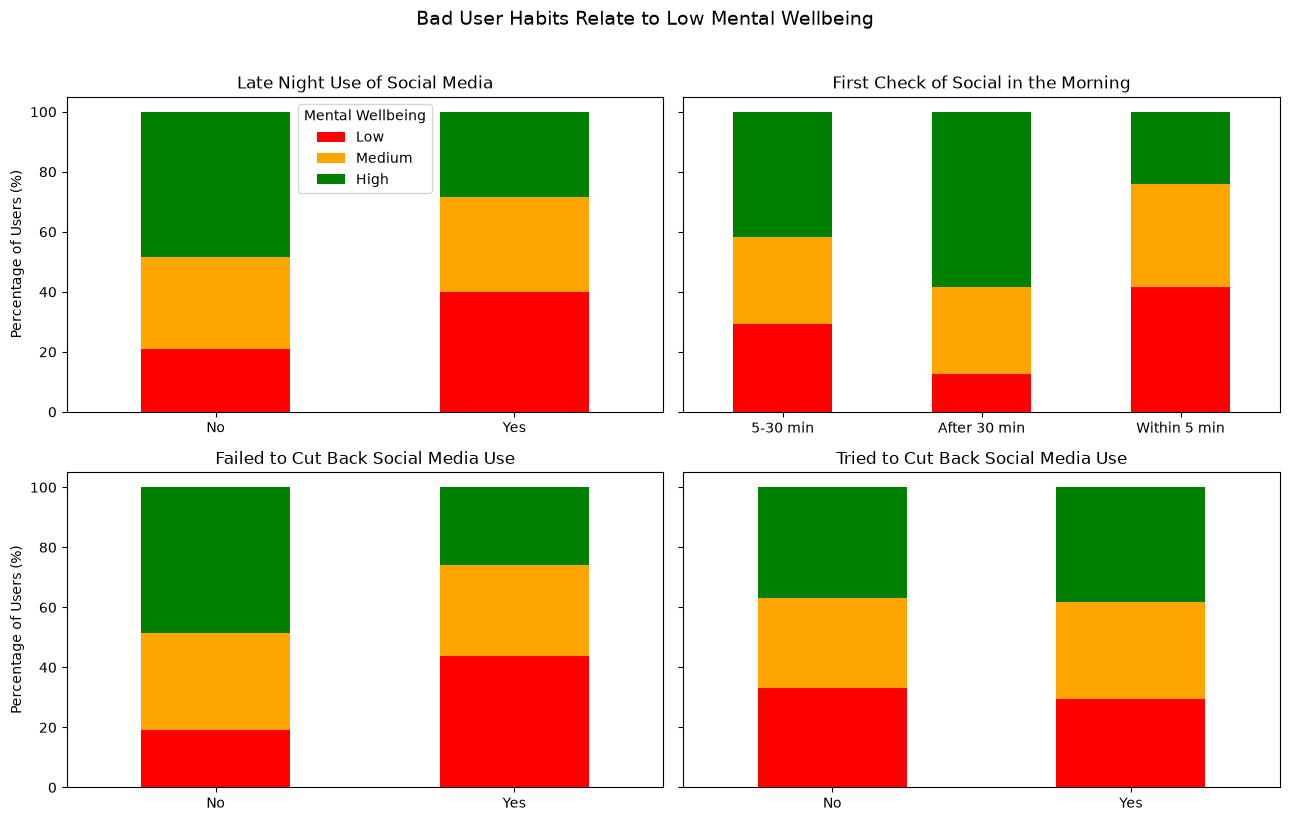

In [25]:
# Bar plots to visualize how different User Habits are related to Mental Wellbeing

# Pick 4 habit feature variables
habits = ["Late_Night_Usage", "First_Check_Morning", "Failed_To_Cut_Back", "Tried_To_Cut_Back"]
titles = ["Late Night Use of Social Media", "First Check of Social in the Morning", "Failed to Cut Back Social Media Use", "Tried to Cut Back Social Media Use"]

fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharey=True)
for ax, col, title in zip(axes.ravel(), habits, titles):
    subset = plot_data.dropna(subset=[col])
    cross_tab_2 = pd.crosstab(subset[col], subset["wellbeing_class"], normalize="index").reindex(columns=classes) * 100
    cross_tab_2.plot(kind="bar", stacked=True, color=[color_palette[c] for c in classes], ax=ax, legend=False)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("Percentage of Users (%)")
    ax.tick_params(axis="x", rotation=0)
axes[0, 0].legend(title="Mental Wellbeing", loc="upper center")
fig.suptitle("Bad User Habits Relate to Low Mental Wellbeing", y=1.02, fontsize=14)
plt.tight_layout()
plt.savefig("images/habits_vs_wellbeing_plots.png")
plt.show()

Observations:

Bad User Habits are relates to Low Mental Wellbeing - a larger percentage of "Low" Mental Wellbeing class:
- late night use of social media
- checking social media within 5 mins in the mornings
- failure to cut back on social media usage

However, whether users tried to cut back social media usage or not does not affect the wellbeing distribution; only the "failures to cut back" counts!

---

[Back to top](#-Index)

### Modeling

With our "clean" dataset in hand, it is now time to build some models.  For this EDA assignment, we will build a simple baseline regression model with `Mental Wellbeing` as the target.  

**Evaluation Metrics**

For this EDA assignment, we will use **Accuracy Score** as our Evaluation Metrics, because the target classes are balanced.

Cleaned Data Grouping for Modeling

| Group | Data Column(s) | Description |
|---|---|---|
| Numeric Features | Numeric data columns | User demographics, social media behavior/habit numeric data conisdered input features
| Categorical Features | String data columns | User demographics and habit string data conisdered input features
| Target | `wellbeing_class` | The target variable - category/class |


Set up Target and Different Predictor Sets

In [26]:
# Split out "wellbeing_class" data as the target
X = clean_data.drop("wellbeing_class", axis = 1)
y = clean_data["wellbeing_class"]


In [27]:
# Convert boolean categorical features Yes/No values to 1/0, and pass it straight through later

for column_name in boo_col_list:
#    print(X[column_name].value_counts())
    X[column_name] = X[column_name].map({'Yes': 1, 'No': 0})
#    print(X[column_name].value_counts())

In [28]:
# Declare different sets for different treatments later

# Numeric Features data column list, without the Boolean Features
num_features = X.select_dtypes(include=["number"]).drop(boo_col_list, axis=1).columns.tolist()                   

# Categorical Features data column list
cat_features = X.select_dtypes(include=["string"]).columns.tolist()    

# Engineered boolean features (yes/no already converted to 1/0) as "passthrough" for encoders later
passthru_features = boo_col_list

# Print set info
print("="*100)
print("MODELING: PREDICTOR MATRIX")
print("="*100)
print("Predictor matrix    :", X.shape)
print("Numeric features    :", len(num_features))
print("Categorical features:", len(cat_features))
print("Passthrough features:", len(passthru_features))
print("-"*100)

MODELING: PREDICTOR MATRIX
Predictor matrix    : (1163, 21)
Numeric features    : 13
Categorical features: 5
Passthrough features: 3
----------------------------------------------------------------------------------------------------


In [29]:
# Build a preprocessor as a reusable function, so we can vary the input numeric list later
# Fill missing numeric values with median values
# Fill missing categorical values with "Unknown"

def make_preprocessor(numeric_cols = num_features):
    return ColumnTransformer(
        transformers = [
            ("num", Pipeline([("impute", SimpleImputer(strategy="median")), 
                              ("scale", StandardScaler())]), numeric_cols),
            ("cat", Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
                              ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_features),
            ("pass", "passthrough", passthru_features)
        ]
    )

preprocessor = make_preprocessor()
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_n

In [30]:
# Check matrix size after data transformation 
n_features_out = make_preprocessor().fit_transform(X).shape[1]

print("="*100)
print("MODELING: DATA PREPROCESSING")
print("="*100)
print("Number of feature columns before data preprocessing:", X.shape[1])
print("Number of feature columns after data preprocessing :", n_features_out)
print("="*100)

MODELING: DATA PREPROCESSING
Number of feature columns before data preprocessing: 21
Number of feature columns after data preprocessing : 39


Train / Test Split

- Create a 20% holdout "test set" for cross-validation to assess models' performance

In [31]:
# Use default random seed 42 to split data into a training set and a held-out testing set
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state = 42, test_size = 0.2)

print(type(X_train), type(y_train))  

<class 'pandas.DataFrame'> <class 'pandas.Series'>


In [32]:
# Print post-split info

print("="*100)
print("MODELING: TRAIN/TEST SPLIT")
print("="*100)
print(f"Train set rows and columns: {X_train.shape}")
print(f"Test set rows and columns : {X_test.shape}")
print("="*100)


MODELING: TRAIN/TEST SPLIT
Train set rows and columns: (930, 21)
Test set rows and columns : (233, 21)


---

#### Baseline

Before we build our first model, we want to establish a baseline. 

In [33]:
# Establish the majority class baseline
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)

baseline_train_acc = dummy.score(X_train, y_train)
baseline_test_acc = dummy.score(X_test, y_test)

# Generate other scoring metrics
# Use Macro-average for scoring multi-class 

baseline_pred = dummy.predict(X_test)

print("="*100)
print("MODELING: MAJORITY BASELINE")
print("="*100)
print(f"Baseline Train set accuracy: {baseline_train_acc:.2%}")
print(f"Baseline Test  set accuracy: {baseline_test_acc:.2%}")
print("-"*100)
print("Baseline precision:", round(precision_score(y_test, baseline_pred, average="macro", zero_division=0), 4))
print("Baseline recall:   ", round(recall_score(y_test, baseline_pred, average="macro", zero_division=0), 4))
print("Baseline F1-macro: ", round(f1_score(y_test, baseline_pred, average="macro"), 4))
print("="*100)


MODELING: MAJORITY BASELINE
Baseline Train set accuracy: 37.63%
Baseline Test  set accuracy: 37.77%
----------------------------------------------------------------------------------------------------
Baseline precision: 0.1259
Baseline recall:    0.3333
Baseline F1-macro:  0.1828


Observation:

Our majority baseline "dummy" model achieves 37% percent accuracy, slightly better than random guessing in 1 out of 3 class labels or 33% 

---

#### A Simple Baseline Model

Develop a simple baseline model to use as a comparison later

Logistic Regression is used for this basic model


In [34]:
# Build a basic model using Logistic Regression with default settings and a pipeline
logreg_pipe = Pipeline([
    ("transformer", make_preprocessor()),
    ("model", LogisticRegression(max_iter=1000)),
])

# Fit the basic model with training set
logreg_pipe.fit(X_train, y_train)
print("Model Fitted:", logreg_pipe.named_steps["model"])
logreg_pipe

Model Fitted: LogisticRegression(max_iter=1000)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('transformer', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['High','Low','Medium']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](21,)","['Age','Gender','Occupation',...,'Offline_Relationship_Quality', 'Physical_Activity_Hrs_Week','Screen_Free_Time_Hrs']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,21
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (d

Scoring Our Simple Baseline Model

For this EDA assignment, we will use **Accuracy Score** as our Evaluation Metrics, because the target classes are balanced.
For future assignment building additional models, we may switch to F1-macro for multi-class.

In [35]:
# Accuracy Scores for the training and test sets, for our simple Logistic Regression model
logreg_train_acc = logreg_pipe.score(X_train, y_train)
logreg_test_acc = logreg_pipe.score(X_test, y_test)

# Get the full picture on the test set with a classification report
logreg_pred = logreg_pipe.predict(X_test)
# logreg_proba = logreg_pipe.predict_proba(X_test)[:, 1]
logreg_proba = logreg_pipe.predict_proba(X_test)
logreg_report_dict = classification_report(y_test, logreg_pred, target_names=classes, output_dict=True)
logreg_roc_auc_ovr = roc_auc_score(y_test, logreg_proba, multi_class="ovr", average="macro",)

print("="*100)
print("Accuracy Scores for the simple Logistic Regression model")
print("-"*100)
print(f"Train set accuracy score: {logreg_train_acc:.2%}")
print(f"Test set accuracy score: {logreg_test_acc:.2%}")
print("Improvement over majority baseline score:", round(logreg_test_acc - baseline_test_acc, 4))
print("="*100)
print("Other Metrics for the simple Logistic Regression model")
print("-"*100)
print(pd.DataFrame(logreg_report_dict).round(4))
print("-"*100)
print("ROC AUC:", round(logreg_roc_auc_ovr, 4))
print("="*100)

Accuracy Scores for the simple Logistic Regression model
----------------------------------------------------------------------------------------------------
Train set accuracy score: 70.75%
Test set accuracy score: 62.66%
Improvement over majority baseline score: 0.2489
Other Metrics for the simple Logistic Regression model
----------------------------------------------------------------------------------------------------
               Low   Medium     High  accuracy  macro avg  weighted avg
precision   0.7529   0.6104   0.4930    0.6266     0.6188        0.6234
recall      0.7273   0.7344   0.4321    0.6266     0.6312        0.6266
f1-score    0.7399   0.6667   0.4605    0.6266     0.6224        0.6227
support    88.0000  64.0000  81.0000    0.6266   233.0000      233.0000
----------------------------------------------------------------------------------------------------
ROC AUC: 0.8164


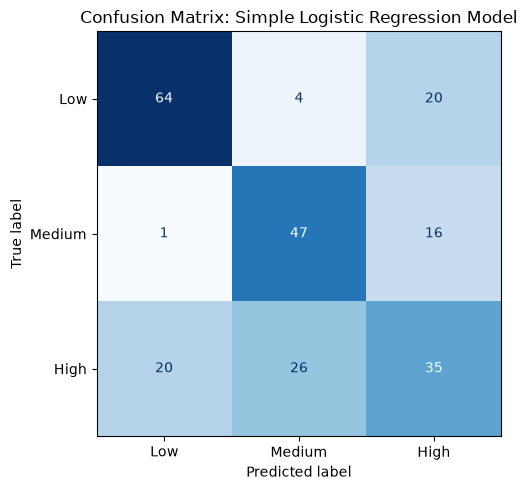

In [36]:
# Evaluate our simple Logistic Regression model using Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, logreg_pred, display_labels=classes,
    cmap="Blues", colorbar=False, ax=ax
)
ax.set_title("Confusion Matrix: Simple Logistic Regression Model")
plt.tight_layout()

plt.savefig("images/c_matrix_logreg.png")
plt.show()

In [37]:
# Extract Feature Importance rankings from our simple Logistic Regression model

importance_df = pd.DataFrame({'Feature': logreg_pipe[:-1].get_feature_names_out(),
                            'Coefficient': logreg_pipe.named_steps["model"].coef_[0],
                            'Abs_Importance': np.abs(logreg_pipe.named_steps["model"].coef_[0])
                            }).sort_values(by='Abs_Importance', ascending=False)

print("="*100)
print("Simple Baseline Model: Feature Importance")
print("="*100)
print("Sorted by importance regardless of sign")
print("-"*100)
print(importance_df)


Simple Baseline Model: Feature Importance
Sorted by importance regardless of sign
----------------------------------------------------------------------------------------------------
                                       Feature  Coefficient  Abs_Importance
38                    pass__Failed_To_Cut_Back    -1.870701        1.870701
36                      pass__Late_Night_Usage    -1.409105        1.409105
35       cat__First_Check_Morning_Within 5 min    -1.187949        1.187949
34       cat__First_Check_Morning_After 30 min     1.128447        1.128447
26              cat__Primary_Platform_Facebook     1.009110        1.009110
5                              num__FOMO_Score    -0.719933        0.719933
6                 num__Social_Comparison_Score    -0.696523        0.696523
8                  num__Scroll_Without_Purpose    -0.686263        0.686263
29                cat__Primary_Platform_TikTok    -0.605842        0.605842
27             cat__Primary_Platform_Instagram    -0.5942

---

[Back to top](#-Index)

### Findings and Recommendations

**Evaluation: Simple Baseline Model**
- Our 3 target classes are roughly balanced (Low, Medium, High for Mental Wellbeing)
- Our simple logistic Regression model improved Accuracy Score by 0.24 over original data set majority baseline
- The model has a Precision Score of 0.75 for predicting a “Low Mental Wellbeing”, which is good for answering our question on *what factors hurt mental wellbeing*. This is confirmed by the Confusion Matrix.

**Factors Hurting Mental Wellbeing** - Feature Importance
- Failed to Cut Back – Failed attempts to cut back on social media is related to lower mental wellbeing
- Late Night Use – More late-night social media use is related to lower mental wellbeing
- First Check Morning – Users checking social media within 5 mins is related to lower mental wellbeing, but after 30 mins is related to better mental wellbeing. i.e., later checks are better for wellbeing
- Daily Usage Hours – Higher daily social media usage hours are mildly related to lower mental wellbeing

**Recommendations to Business**
- Healthy marketing hours: Publish social media advertisements between late morning and before night fall are better for users’ wellbeing
- Platform choice: Focus advertising on Facebook, as Facebook users tend to have better mental wellbeing (and therefore maybe better buyers)



---

[Back to top](#-Index)

### Next Steps

**Build and Evaluate Additional Models**

Build other Machine Learning models such as K-Nearest Neighbors, Decision Tree, SVM, and Ensemble technique with Random Forest.  Use Grid Search to find the best hyperparameters for these models, then compare resulting performance metrics with our simple baseline model for possible improvements

**Fine-Tune Best Model**

Determine the best model for this scenario, and look for fine-tuning opportunities to further improve the model e.g., decision thresholds 
